# Project: Linear and Decision Tree Regression on Boston Housing and Iris Dataset
## A-Boston Housing Dataset
### Context
This study of the "Boston Housing" dataset aims to analyze and predict the median value of owner-occupied homes in various areas of Boston. This dataset, collected by the U.S. Census Service, includes information on 14 variables, such as per capita crime rate, the proportion of residential land zoned for large lots, the average number of rooms per dwelling, and the property tax rate. The objective is to use these socioeconomic and environmental characteristics to build a regression model capable of accurately predicting home values, thereby providing valuable insights for real estate market participants, urban planners, and policymakers.
### Variables descriptions 
**crim:** Per capita crime rate by town

**zn:** Proportion of residential land zoned for lots over 25,000 sq.ft.

**indus:** Proportion of non-retail business acres per town

**chas:** Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
   
**nox:** Nitric oxides concentration (parts per 10 million)

**rm:** Average number of rooms per dwelling

**age:** Proportion of owner-occupied units built prior to 1940

**dis:** Weighted distances to five Boston employment centres

**rad:** Index of accessibility to radial highways

**tax:** Full-value property-tax rate per $10,000 
  
**ptratio:** Pupil-teacher ratio by town

**b:** 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town

**lstat:** % lower status of the population

**medv:** Median value of owner-occupied homes in $1000's   

### Cleaning and Explanatory Data Analysis

In [43]:
#Libraries used
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
# Data loading
data = pd.read_csv("C:/Users/loukm/Desktop/Master 1/Machine Learning/BostonHousing.csv")
data.head(10)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9


In [45]:
# General info about Dataframe
data.info()

# Descriptive statistical
data.describe()

# Missing values
data.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       501 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


crim       0
zn         0
indus      0
chas       0
nox        0
rm         5
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

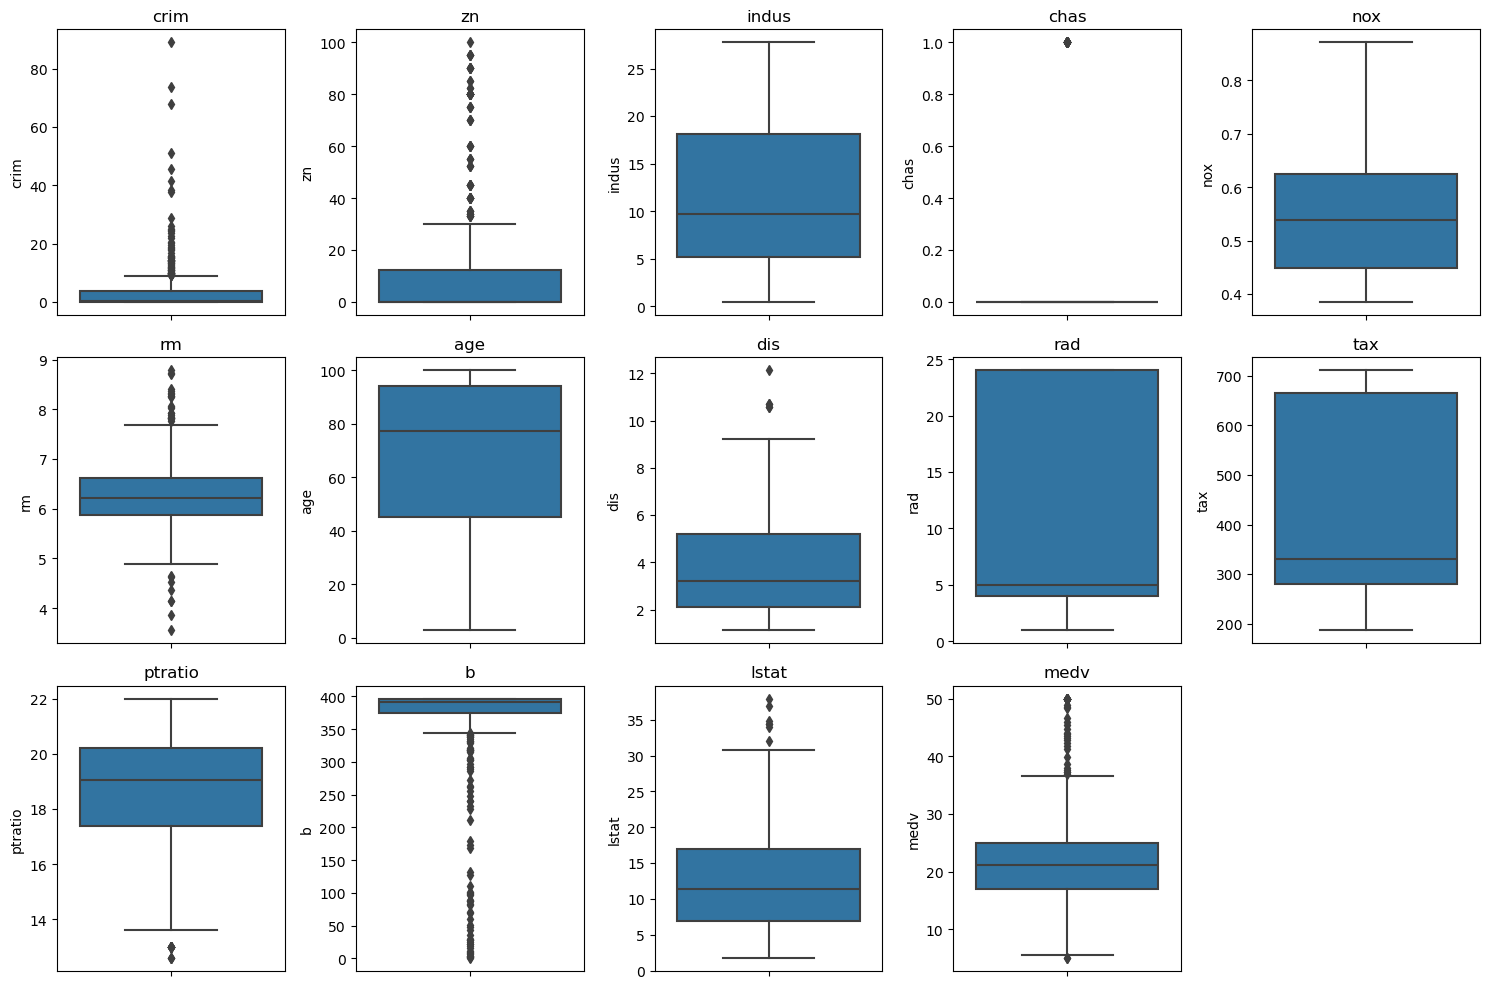

In [46]:
# Boxplot for each variable
plt.figure(figsize=(15, 10))
for i, col in enumerate(data.columns):
    plt.subplot(3, 5, i+1)
    sns.boxplot(y=data[col])
    plt.title(col)
plt.tight_layout()
plt.show()

The boxplots reveal a variety of distributions across the features in the Boston housing dataset.  We observe a strong right skew in the crime rate (crim) and the proportion of residential land zoned for large lots (zn), indicating the presence of high outliers. The concentration of nitric oxides (nox) and the proportion of older housing units (age) show more symmetrical distributions, while distances to employment centers (dis) and radial highway accessibility (rad) exhibit right skewness, suggesting distant outliers. The property tax rate (tax) and pupil-teacher ratio (ptratio) are relatively symmetrical. The proportion of Black residents (b) is heavily left-skewed, and lower status of the population (lstat) is slightly right-skewed. The median home value (medv) displays a relatively symmetrical distribution with some high outliers. These observations highlight the need to address outliers and skewness to improve the performance of predictive models.

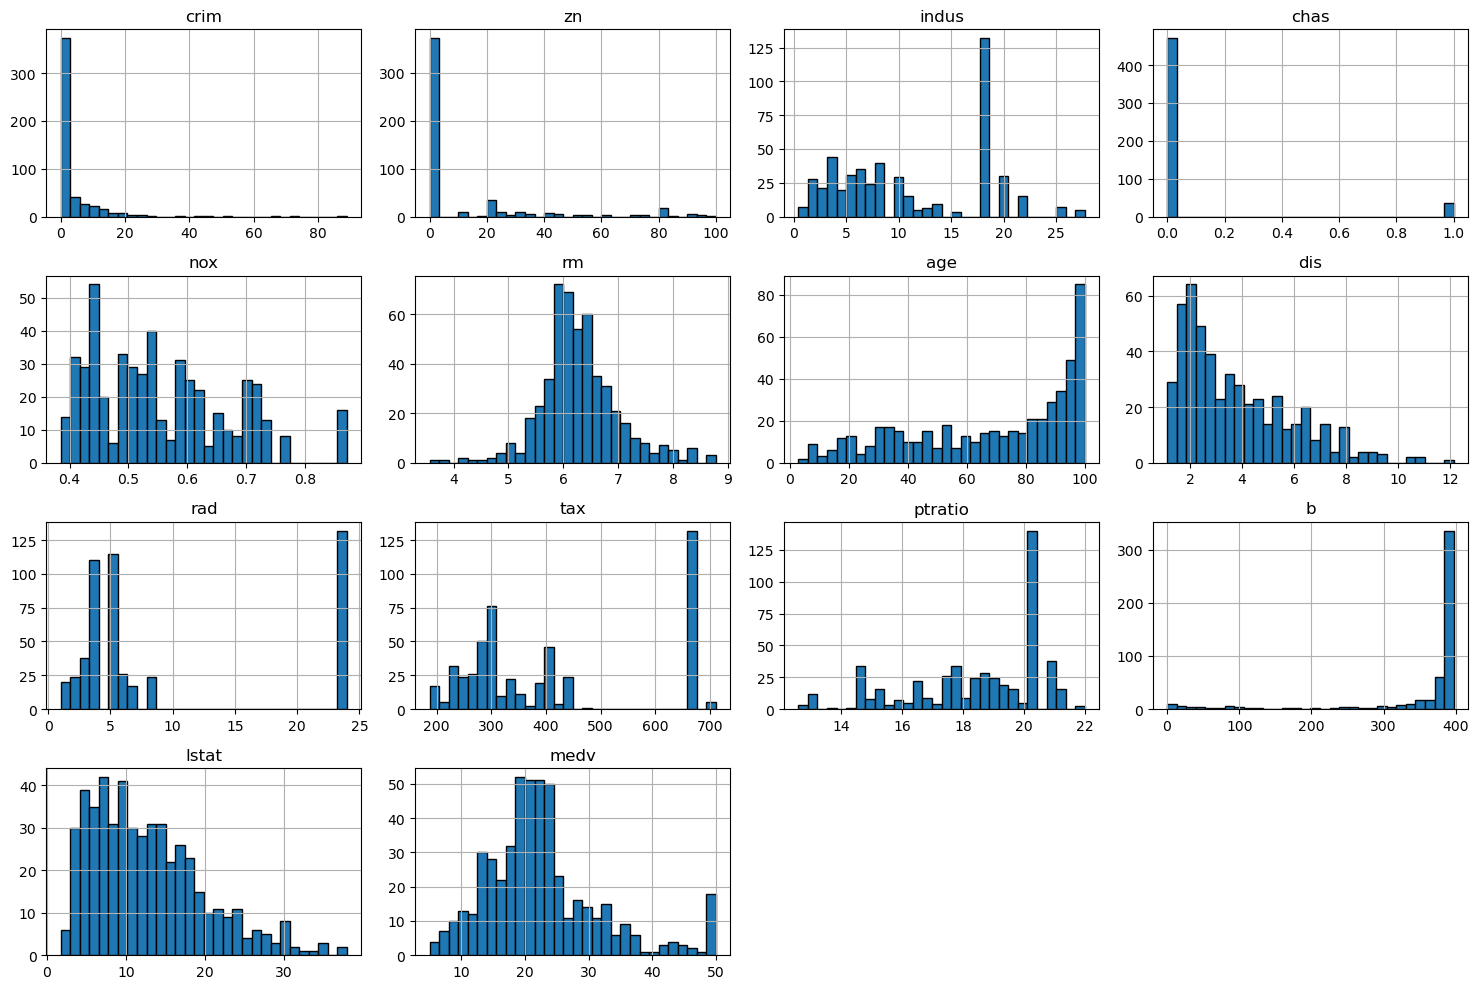

In [47]:
# Histogram for each variable
data.hist(figsize=(15, 10), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

The histograms provide a clear overview of the distribution patterns for various features in the Boston housing dataset. Notably, several features exhibit significant skewness, indicating a non-uniform distribution of values. The crime rate (crim) and the proportion of residential land zoned for large lots (zn) are heavily right-skewed, suggesting a concentration of lower values with a few high outliers. The distribution of nitric oxides concentration (nox) and the average number of rooms (rm) appear more symmetrical, implying a more even spread of values. Conversely, the proportion of older housing units (age) and the distance to employment centers (dis) are right-skewed, indicating higher values in some towns. The index of accessibility to radial highways (rad) and the property tax rate (tax) show discrete distributions with distinct peaks, likely reflecting specific categories or levels. The pupil-teacher ratio (ptratio) is left-skewed, suggesting lower ratios are more common. The proportion of Black residents (b) is heavily left-skewed, indicating a high concentration of towns with a large proportion of Black residents. The lower status of the population (lstat) is slightly right-skewed, and the median home value (medv) shows a relatively symmetrical distribution with a few high outliers.

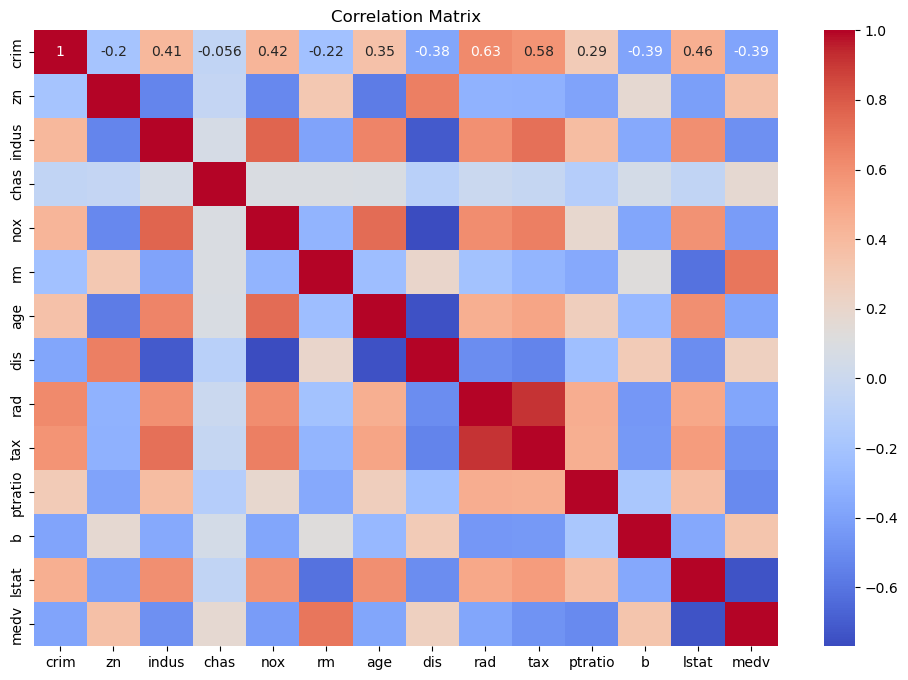

In [48]:
# Correlation Matrix
corr_matrix = data.corr()
# Correlation Matrix Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

The correlation matrix reveals significant linear relationships among the variables in the Boston housing dataset. The median value of homes (medv) exhibits a strong negative correlation with the lower status of the population (lstat) and a notable positive correlation with the average number of rooms per dwelling (rm), highlighting the socio-economic impact and housing size on prices. The crime rate (crim) and nitric oxides concentration (nox) are positively correlated with the lower status of the population, suggesting environmental and social challenges in these areas. The index of accessibility to radial highways (rad) is strongly correlated with the full-value property-tax rate (tax), indicating a possible fiscal policy tied to infrastructure.

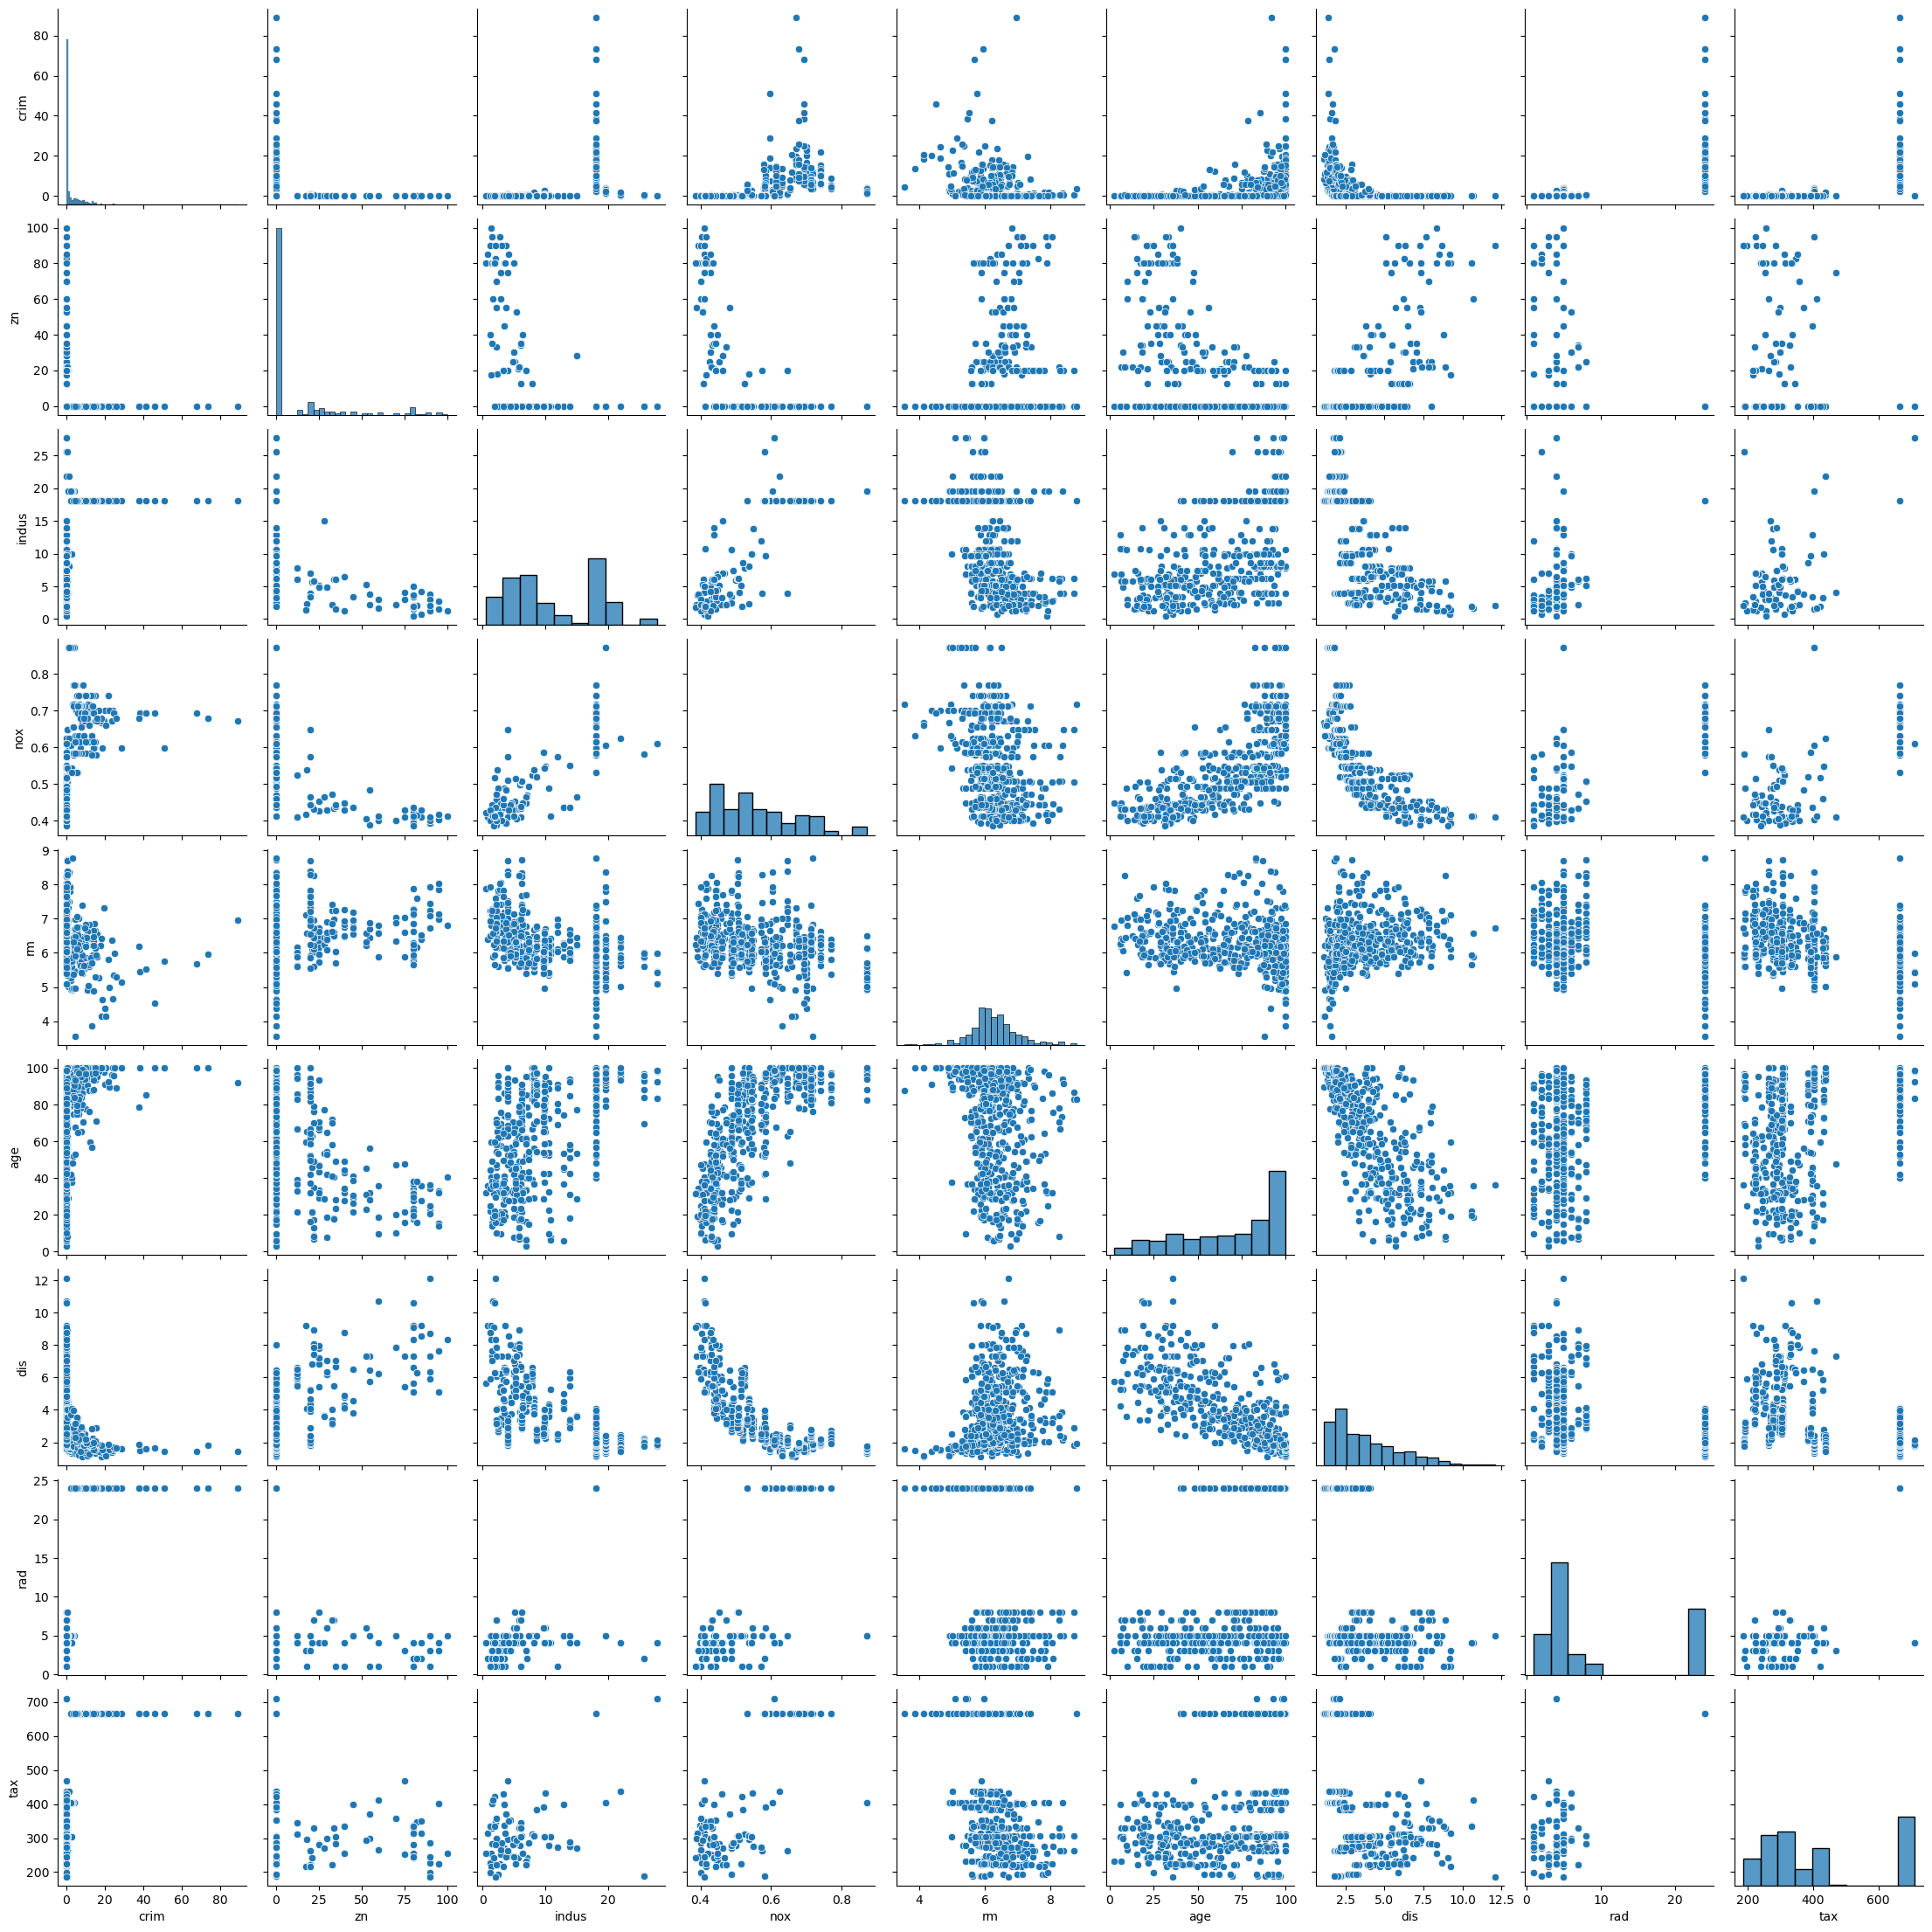

In [49]:
#Scatter Plot
sns.pairplot(data[['crim', 'zn', 'indus', 'nox', 'rm', 'age', 'dis', 'rad','tax']])
plt.show()

This pairplot reveals intricate relationships between variables in the Boston housing dataset. Scatterplots highlight a negative correlation between median home value (medv) and lower status of the population (lstat), confirming socioeconomic influence on prices. The average number of rooms (rm) shows a positive correlation with medv, indicating larger homes tend to be more expensive. Crime rate (crim) and nitric oxides concentration (nox) display skewed distributions and varied relationships, suggesting modeling challenges. Radial highway accessibility (rad) and property tax rate (tax) exhibit discrete relationships, likely reflecting specific policies.

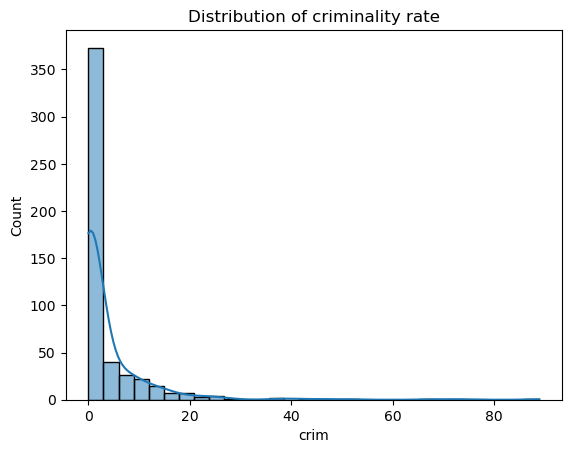

In [50]:
# Distribution of criminality rate
sns.histplot(data['crim'], bins=30, kde=True)
plt.title('Distribution of criminality rate')
plt.show()

The histogram depicts the distribution of the per capita crime rate (crim) across towns in the Boston housing dataset. It reveals a highly right-skewed distribution, indicating that the majority of towns experience low crime rates, clustered near zero. However, there is a long tail extending to the right, signifying the presence of a few towns with significantly higher crime rates.

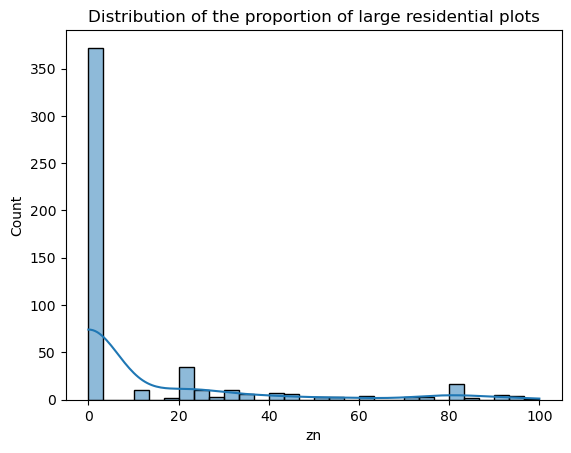

In [51]:
# Distribution of the proportion of large residential plots
sns.histplot(data['zn'], bins=30, kde=True)
plt.title('Distribution of the proportion of large residential plots')
plt.show()

The histogram illustrates the distribution of the proportion of residential land zoned for lots over 25,000 square feet (zn) in the Boston housing dataset. The data demonstrates a highly right-skewed pattern, with the vast majority of towns having a very low proportion of such large residential plots, clustered near zero. This is evident from the tall bar at the far left of the histogram. However, the distribution also shows a long tail extending towards higher values, indicating that a few towns have a significantly larger proportion of these large residential plots.

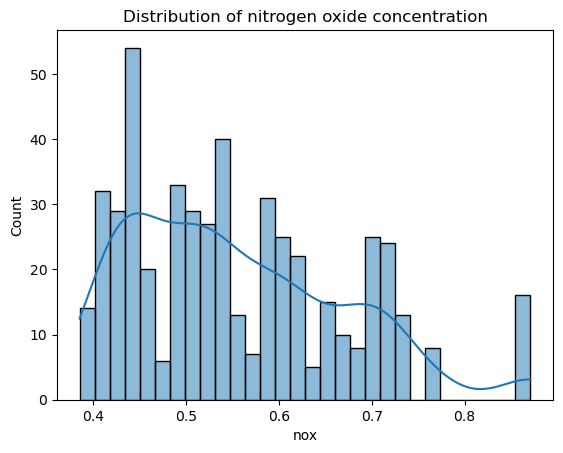

In [52]:
# Distribution of nitrogen oxide concentration
sns.histplot(data['nox'], bins=30, kde=True)
plt.title('Distribution of nitrogen oxide concentration')
plt.show()

This histogram displays the distribution of nitric oxides concentration (nox) in the Boston housing dataset. The data exhibits a multimodal pattern, suggesting the presence of distinct clusters or categories of towns with varying nox levels. There are several peaks throughout the distribution, indicating that towns tend to group around specific concentration values rather than being evenly spread.

In [53]:
# Handle Outliers
def detect_outliers_iqr(column):
    Q1 = column.quantile(0.25)  
    Q3 = column.quantile(0.75) 
    IQR = Q3 - Q1 
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = column[(column < lower_bound) | (column > upper_bound)]
    return outliers
outliers_dict = {}
for col in data.select_dtypes(include=[np.number]).columns:
    outliers = detect_outliers_iqr(data[col])
    if not outliers.empty:
        outliers_dict[col] = outliers
for col, outliers in outliers_dict.items():
    print(f"Valeurs aberrantes dans la colonne '{col}':")
    print(outliers)
    print("\n")

    # Apply a logarithmic transformation
data_log = data.copy()
for col in outliers_dict.keys():
    data_log[col] = np.log1p(data_log[col])
print(data_log.head())

Valeurs aberrantes dans la colonne 'crim':
367    13.5222
371     9.2323
373    11.1081
374    18.4982
375    19.6091
        ...   
468    15.5757
469    13.0751
477    15.0234
478    10.2330
479    14.3337
Name: crim, Length: 66, dtype: float64


Valeurs aberrantes dans la colonne 'zn':
39     75.0
40     75.0
54     75.0
55     90.0
56     85.0
       ... 
351    60.0
352    60.0
353    90.0
354    80.0
355    80.0
Name: zn, Length: 68, dtype: float64


Valeurs aberrantes dans la colonne 'chas':
142    1
152    1
154    1
155    1
160    1
162    1
163    1
208    1
209    1
210    1
211    1
212    1
216    1
218    1
219    1
220    1
221    1
222    1
234    1
236    1
269    1
273    1
274    1
276    1
277    1
282    1
283    1
356    1
357    1
358    1
363    1
364    1
369    1
370    1
372    1
Name: chas, dtype: int64


Valeurs aberrantes dans la colonne 'rm':
97     8.069
98     7.820
162    7.802
163    8.375
166    7.929
180    7.765
186    7.831
195    7.875
203    7.

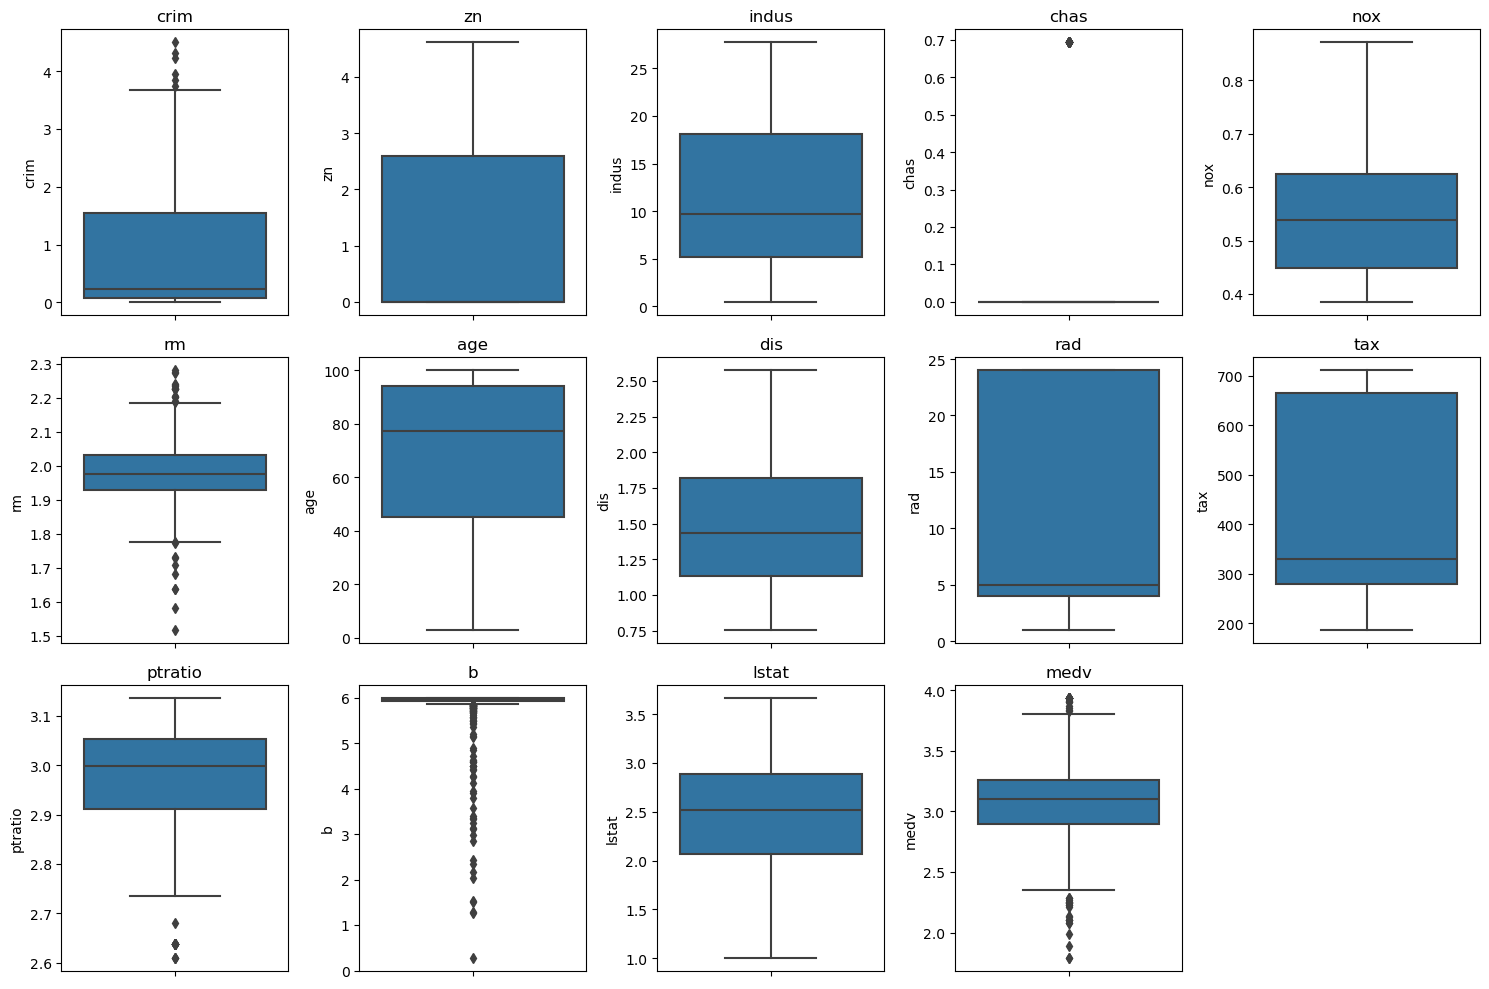

In [54]:
# Boxplot after outlier management
plt.figure(figsize=(15, 10))
for i, col in enumerate(data_log.select_dtypes(include=[np.number]).columns):
    plt.subplot(3, 5, i+1)
    sns.boxplot(y=data_log[col])
    plt.title(col)
plt.tight_layout()
plt.show()

The boxplots reveal significant distributional variations across the Boston housing dataset, with features like crime rate and large lot zoning exhibiting strong right skewness and numerous high outliers. Industrial land and nitric oxide concentrations show relatively symmetrical distributions with minor outliers, while binary and near-normal distributions contrast with left-skewed variables like age and pupil-teacher ratio. Distance to employment, highway accessibility, property tax, and lower status of the population display right-skewed distributions with outliers.

### Regression and Predictons 
#### Linear Regression 

In [55]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer


# Define features (X) and target variable (y)
X = data_log.drop("medv", axis=1)
y = data_log["medv"]

# Imputation
imputer = SimpleImputer(strategy='mean')
X_imp = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_imp, y, test_size=0.2, random_state=42)

# Defining and training model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluate model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f'Coefficient of Determination (R²): {r2:.2f}')
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Squared Error (MSE): 0.03
Coefficient of Determination (R²): 0.78
Root Mean Squared Error (RMSE): 0.17


### Decision Tree Regression

In [56]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.impute import SimpleImputer

# Define features (X) and target variable (y)
X = data_log.drop('medv', axis=1)
y = data_log['medv']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

# Create and train the model
regressor = DecisionTreeRegressor(max_depth=5, random_state=42)
regressor.fit(X_train, y_train)

# Make predictions
y_pred = regressor.predict(X_test)

# Calculate Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'Coefficient of Determination (R²): {r2:.2f}')
print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Coefficient of Determination (R²): 0.76
Mean Squared Error (MSE): 0.03
Root Mean Squared Error (RMSE): 0.18


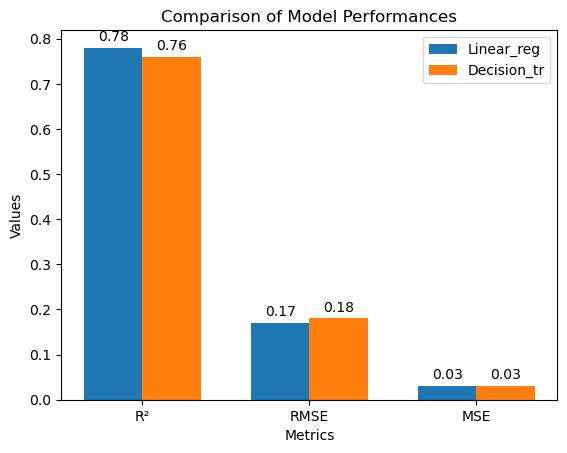

In [57]:
# Metrics for the two models
model1_metrics = {'R²': 0.78, 'RMSE': 0.17, 'MSE': 0.03}
model2_metrics = {'R²': 0.76, 'RMSE': 0.18, 'MSE': 0.03}

# Names of metrics and models
metrics = ['R²', 'RMSE', 'MSE']
models = ['Model 1', 'Model 2']

# Create a bar chart
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, [model1_metrics[m] for m in metrics], width, label='Linear_reg')
rects2 = ax.bar(x + width/2, [model2_metrics[m] for m in metrics], width, label='Decision_tr')

# Add labels and a title
ax.set_xlabel('Metrics')
ax.set_ylabel('Values')
ax.set_title('Comparison of Model Performances')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# Display values on the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # Vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.show()

The image presents a bar chart comparing the performance of two models, "Linear_reg" and "Decision_tr," across three metrics: R², RMSE, and MSE. "Linear_reg" displays an R² of 0.78, an RMSE of 0.17, and an MSE of 0.03, while "Decision_tr" has an R² of 0.76, an RMSE of 0.18, and an MSE of 0.03. The "Linear_reg" model is slightly more performant than "Decision_tr" because it exhibits a higher R², indicating a better fit to the data, and a lower RMSE, signifying smaller prediction errors. The MSE, although identical for both models, confirms comparable performance in terms of mean squared error.

## B-Iris Dataset
### Context 
The study of the Iris dataset, introduced by Ronald Fisher in 1936, is a benchmark in machine learning for classification. This dataset, consisting of 150 samples of iris flowers, aims to distinguish three species: setosa, versicolor, and virginica, based on four measurable features. These variables include the length and width of sepals (sepal length, sepal width) and the length and width of petals (petal length, petal width), all measured in centimeters. The primary objective is to use these measurements to build classification models capable of predicting the iris species from the dimensions of its sepals and petals.

In [58]:
# Load dataset
iris = pd.read_csv("C:/Users/loukm/Desktop/Master 1/Machine Learning/iris.csv")
print(iris.head(10))

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
5           5.4          3.9           1.7          0.4  setosa
6           4.6          3.4           1.4          0.3  setosa
7           5.0          3.4           1.5          0.2  setosa
8           4.4          2.9           1.4          0.2  setosa
9           4.9          3.1           1.5          0.1  setosa


In [59]:
# General info about Dataframe
iris.info()

# Descriptive statistical
iris.describe()

# Missing values
iris.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

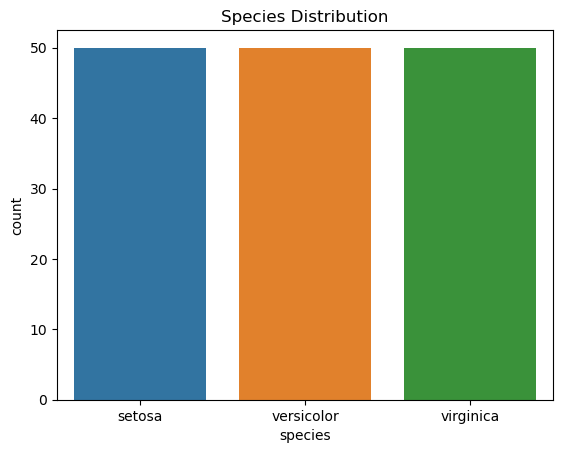

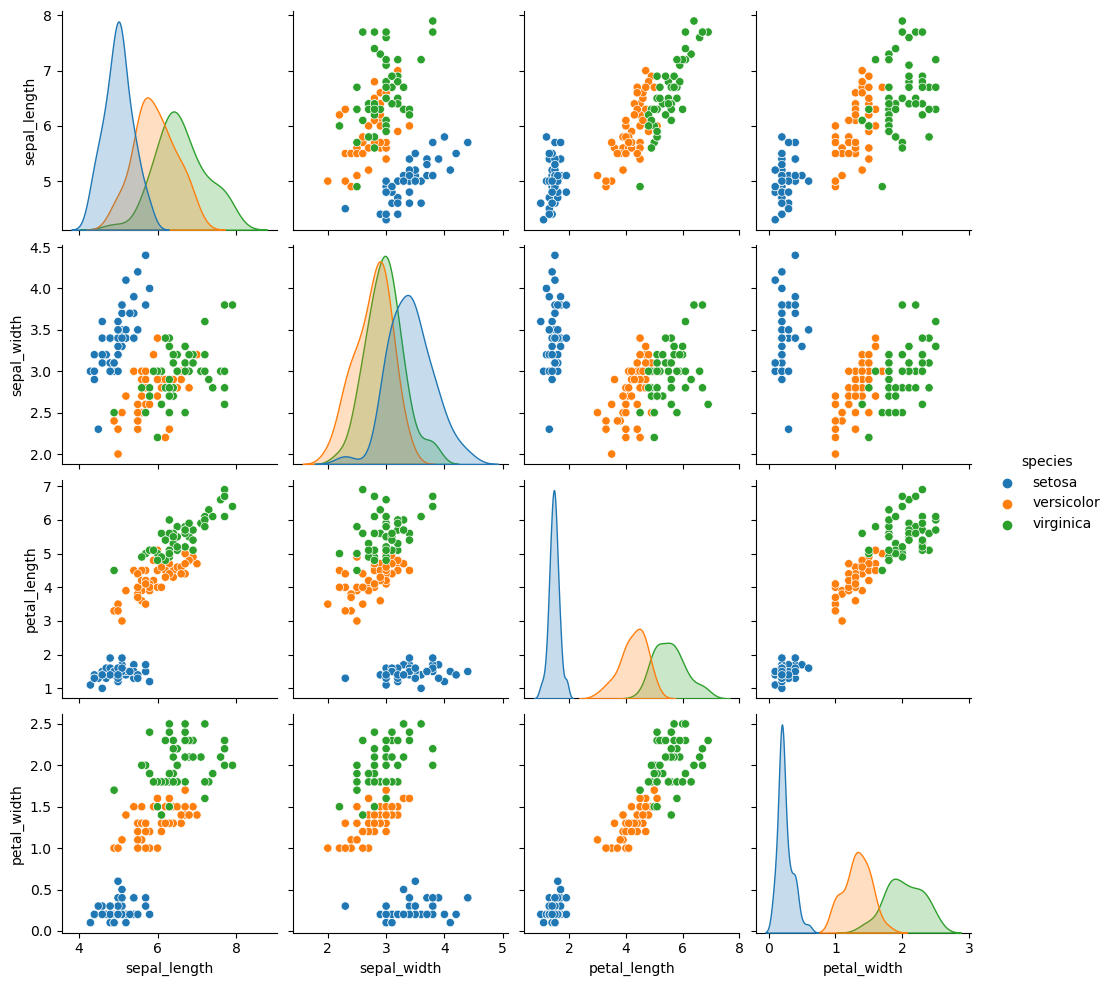

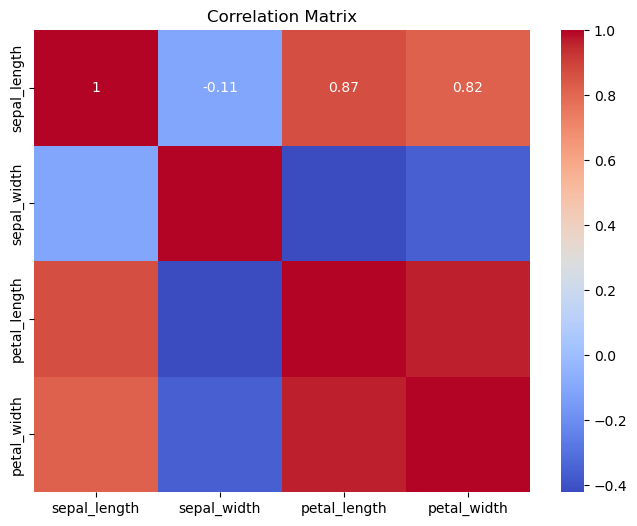

In [60]:
# Distribution of species
sns.countplot(x='species', data=iris)
plt.title('Species Distribution')
plt.show()

# Pairplot to visualize relationships between variables
sns.pairplot(iris, hue='species')
plt.show()

# Heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(iris.drop('species', axis=1).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

**1** The bar chart presents the distribution of species within the Iris dataset, showcasing a perfectly balanced representation with 50 occurrences for each species: setosa, versicolor, and virginica.

**2** This pairplot illustrates the relationships between sepal length, sepal width, petal length, and petal width for three Iris species: setosa, versicolor, and virginica. On the diagonal, kernel density estimation (KDE) plots show the distribution of each feature, revealing that setosa tends to have smaller petal dimensions, while versicolor and virginica overlap more. The scatterplots off the diagonal display pairwise relationships; for instance, petal length and width are highly correlated, especially for versicolor and virginica, suggesting these features are strong discriminators. Sepal dimensions show more overlap, but setosa is still distinguishable. Overall, the plot indicates that petal features are more effective in species separation compared to sepal features.

**3** This correlation matrix visualizes the linear relationships between sepal length, sepal width, petal length, and petal width in the Iris dataset. Notably, petal length and petal width exhibit a strong positive correlation (0.87), suggesting that as petal length increases, petal width tends to increase as well, and vice versa. Sepal length also shows a moderately strong positive correlation with both petal length (0.87) and petal width (0.82), indicating similar trends. In contrast, sepal width has a weak negative correlation with sepal length (-0.11), suggesting a slight inverse relationship. These correlations highlight that petal dimensions are highly interrelated, while sepal dimensions show a weaker relationship, implying that petal features might be more informative for distinguishing Iris species.

In [61]:
# Separate features and target
X = iris.drop('species', axis=1)
y = iris['species']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [62]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Accuracy: 1.00

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



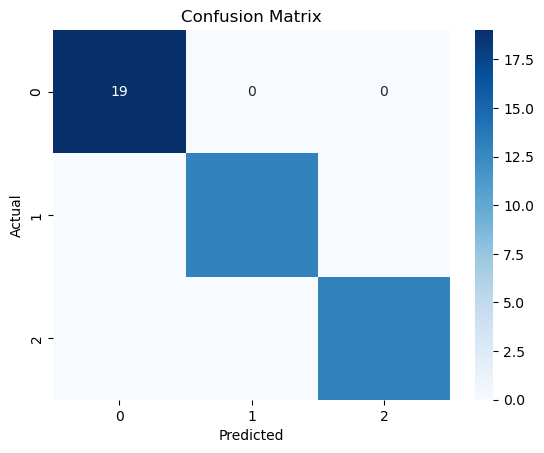

In [63]:
# Create and train the Decision Tree Classifier model
classifier = DecisionTreeClassifier(max_depth=3, random_state=42)
classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

This confusion matrix displays the classification model's results for three classes, numbered 0, 1, and 2, where class 0 was perfectly predicted with 19 true positives and no classification errors.

# END